# Each condition vs 22 °C
22 °C is shown once. Each condition's histogram (with the 22 °C curve dashed for reference) sits above its difference from 22 °C (condition − 22 °C, direct subtraction of the kernel density curves). All replicates pooled; every track counts equally.

Set `data_dir` and run the cell.

32 °C, 5 min: 11.0% of tracks shifted relative to 22 °C
32 °C, 15 min: 14.1% of tracks shifted relative to 22 °C
Recovery 5 min: 13.1% of tracks shifted relative to 22 °C
Recovery 15 min: 10.1% of tracks shifted relative to 22 °C
Recovery 30 min: 5.5% of tracks shifted relative to 22 °C


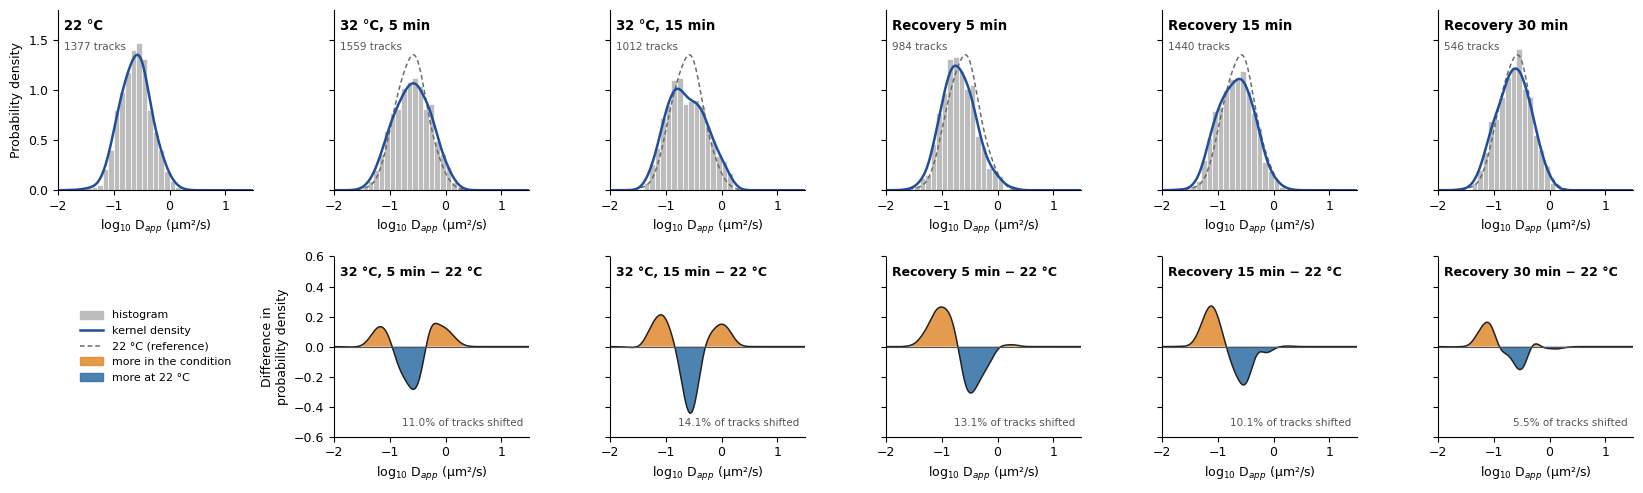

saved all_conditions_vs_22deg.svg, 22deg_histogram.svg and one *_vs_22deg.svg per condition


In [2]:
# ---------------------------------------------------------------- settings
import os
data_dir  = r"\\home.org.aalto.fi\tomase1\data\Documents\Aalto\Manuscripts\SMT Psychrobacter\DATA\clpx_clean_csvs_simple_cut"     # folder with the *_clean.csv files
reference = ("clpx_22deg_clean.csv", "22 °C")        # shown once; subtracted from every condition
conditions = [                                       # (file name, title on the plot)
    ("clpx_32HS_5min_clean.csv",   "32 °C, 5 min"),
    ("clpx_32HS_15min_clean.csv",  "32 °C, 15 min"),
    ("clpx_22REC_5min_clean.csv",  "Recovery 5 min"),
    ("clpx_22REC_15min_clean.csv", "Recovery 15 min"),
    ("clpx_22REC_30min_clean.csv", "Recovery 30 min"),
]
bin_width = 0.1           # histogram bin width (log10 units)
kde_bw    = 0.11          # KDE smoothing (log10 units), the same for every curve
x_range   = (-2, 1.5)     # x-axis limits (log10 µm²/s)
y_hist    = 1.8           # y-axis maximum of the histogram panels
y_diff    = (-0.6, 0.6)   # y-axis of the difference panels
show_reference_line = True   # dashed 22 °C curve on every condition histogram

# ---------------------------------------------------------------- code
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from matplotlib.lines import Line2D

HIST, KDE, REF = "#BDBDBD", "#1F4E9C", "#6B6B6B"
MORE, LESS, BAND = "#E08A2E", "#2E6DA4", "#9E9E9E"
plt.rcParams.update({"font.family": "DejaVu Sans", "font.size": 9, "svg.fonttype": "none"})
KEY, CELL = ["fov_mask_id", "cell_id_int", "particle"], ["fov_mask_id", "cell_id_int"]
bins = np.arange(x_range[0], x_range[1] + bin_width, bin_width)
xs = np.linspace(*x_range, 701)
dx = xs[1] - xs[0]
kx = np.arange(-4 * kde_bw, 4 * kde_bw + dx, dx)
kernel = np.exp(-0.5 * (kx / kde_bw) ** 2); kernel /= kernel.sum() * dx
xticks = np.arange(np.ceil(x_range[0]), x_range[1] + 0.01, 1)


def load(fname):
    """log10 Dapp of every track (one value per track), grouped per cell."""
    t = pd.read_csv(os.path.join(data_dir, fname)).groupby(KEY, as_index=False)["Dapp"].first()
    t["logD"] = np.log10(t["Dapp"])
    return [g["logD"].to_numpy() for _, g in t.groupby(CELL)]


def density(cells):
    """Gaussian kernel density on xs; every track counts equally."""
    v = np.concatenate(cells)
    h, _ = np.histogram(v, bins=np.r_[xs - dx / 2, xs[-1] + dx / 2])
    return np.convolve(h, kernel, mode="same") / len(v)


def resample(cells, rng):
    return [cells[i] for i in rng.integers(0, len(cells), len(cells))]


def tidy(ax):
    for side in ("top", "right"): ax.spines[side].set_visible(False)
    ax.set_xlim(*x_range); ax.set_xticks(xticks)


def hist_panel(ax, cells, title, ref_line=None):
    v = np.concatenate(cells)
    ax.hist(v, bins=bins, density=True, color=HIST, edgecolor="white", linewidth=0.5)
    if ref_line is not None:
        ax.plot(xs, ref_line, color=REF, lw=1.1, ls=(0, (3, 2)))
    ax.plot(xs, density(cells), color=KDE, lw=1.8)
    ax.set_ylim(0, y_hist)
    ax.text(0.03, 0.95, title, transform=ax.transAxes, va="top", fontsize=9.5, fontweight="bold")
    ax.text(0.03, 0.82, f"{len(v)} tracks", transform=ax.transAxes, va="top", fontsize=7.5, color="#555555")
    ax.set_xlabel(r"log$_{10}$ D$_{app}$ (µm²/s)")
    tidy(ax)


def diff_panel(ax, diff, lo, hi, title):
    if lo is not None:
        ax.fill_between(xs, lo, hi, color=BAND, alpha=0.35, lw=0)
    ax.fill_between(xs, diff, 0, where=diff > 0, color=MORE, alpha=0.85, lw=0)
    ax.fill_between(xs, diff, 0, where=diff < 0, color=LESS, alpha=0.85, lw=0)
    ax.plot(xs, diff, color="#222222", lw=1.1)
    ax.axhline(0, color="#555555", lw=0.8)
    ax.set_ylim(*y_diff)
    ax.text(0.03, 0.95, f"{title} − {reference[1]}", transform=ax.transAxes, va="top", fontsize=9, fontweight="bold")
    ax.text(0.97, 0.05, f"{0.5 * np.abs(diff).sum() * dx * 100:.1f}% of tracks shifted",
            transform=ax.transAxes, ha="right", va="bottom", fontsize=7.5, color="#555555")
    ax.set_xlabel(r"log$_{10}$ D$_{app}$ (µm²/s)")
    tidy(ax)


def legend_items():
    h = [Patch(color=HIST), Line2D([], [], color=KDE, lw=1.8)]
    l = ["histogram", "kernel density"]
    if show_reference_line:
        h.append(Line2D([], [], color=REF, lw=1.1, ls=(0, (3, 2)))); l.append(f"{reference[1]} (reference)")
    h += [Patch(color=MORE, alpha=0.85), Patch(color=LESS, alpha=0.85)]
    l += ["more in the condition", f"more at {reference[1]}"]
    return h, l


# ---- calculations
ref_cells = load(reference[0])
ref_density = density(ref_cells)
results = []
for fname, title in conditions:
    cells = load(fname)
    diff = density(cells) - ref_density
    lo = hi = None                                   # no confidence band: direct subtraction
    results.append((fname, title, cells, diff, lo, hi))
    print(f"{title}: {0.5 * np.abs(diff).sum() * dx * 100:.1f}% of tracks shifted relative to {reference[1]}")
ref_line = ref_density if show_reference_line else None

# ---- overview: 22 °C once (top left), each condition above its difference
n = len(results)
fig, axs = plt.subplots(2, n + 1, figsize=(2.75 * (n + 1), 5.0), gridspec_kw={"height_ratios": [1, 1]})
hist_panel(axs[0, 0], ref_cells, reference[1])
axs[0, 0].set_ylabel("Probability density")
axs[1, 0].axis("off")
h, l = legend_items()
axs[1, 0].legend(h, l, loc="center", frameon=False, fontsize=8)
for j, (fname, title, cells, diff, lo, hi) in enumerate(results, start=1):
    hist_panel(axs[0, j], cells, title, ref_line)
    diff_panel(axs[1, j], diff, lo, hi, title)
    axs[0, j].tick_params(labelleft=False)
    if j > 1: axs[1, j].tick_params(labelleft=False)
axs[1, 1].set_ylabel("Difference in\nprobability density")
fig.tight_layout(h_pad=1.2, w_pad=0.6)
fig.savefig("all_conditions_vs_22deg.svg", bbox_inches="tight")
plt.show()

# ---- separate files: 22 °C on its own, and each condition (histogram above its difference)
fig, ax = plt.subplots(figsize=(3.3, 2.5))
hist_panel(ax, ref_cells, reference[1]); ax.set_ylabel("Probability density")
fig.tight_layout(); fig.savefig("22deg_histogram.svg", bbox_inches="tight"); plt.close(fig)
for fname, title, cells, diff, lo, hi in results:
    fig, axs2 = plt.subplots(2, 1, figsize=(3.3, 4.8), sharex=True)
    hist_panel(axs2[0], cells, title, ref_line); axs2[0].set_ylabel("Probability density"); axs2[0].set_xlabel("")
    diff_panel(axs2[1], diff, lo, hi, title); axs2[1].set_ylabel("Difference in\nprobability density")
    fig.tight_layout(h_pad=0.8)
    fig.savefig(fname.replace("_clean.csv", "_vs_22deg.svg"), bbox_inches="tight"); plt.close(fig)
print("saved all_conditions_vs_22deg.svg, 22deg_histogram.svg and one *_vs_22deg.svg per condition")


In [6]:
import numpy as np, pandas as pd, os

slow_cut, fast_cut = 0.1, 0.6          # thresholds in µm²/s; change here if you like
rows = []
for fname, title in [reference] + conditions:
    cells = load(fname)                                  # same loading as the figure
    logD = np.concatenate(cells)                         # one log10 Dapp per trajectory
    D = 10 ** logD
    kde = density(cells)                                 # same blue curve as in the figure
    shifted = 0.5 * np.abs(kde - ref_density).sum() * dx * 100 if fname != reference[0] else np.nan
    rows.append({
        "condition": title,
        "trajectories": len(D),
        "cells": len(cells),
        "median (µm²/s)": round(np.median(D), 3),
        "Q1 (µm²/s)": round(np.percentile(D, 25), 3),
        "Q3 (µm²/s)": round(np.percentile(D, 75), 3),
        "curve maximum (µm²/s)": round(10 ** xs[kde.argmax()], 3),
        f"% below {slow_cut}": round((D < slow_cut).mean() * 100, 1),
        f"% above {fast_cut}": round((D > fast_cut).mean() * 100, 1),
        f"% between {slow_cut} and {fast_cut}": round(((D >= slow_cut) & (D <= fast_cut)).mean() * 100, 1),
        "% shifted vs 22 °C": round(shifted, 1),
    })
summary = pd.DataFrame(rows)
summary.to_excel("Dapp_summary_per_condition.xlsx", index=False)
summary

,condition,trajectories,cells,median (µm²/s),Q1 (µm²/s),Q3 (µm²/s),curve maximum (µm²/s),% below 0.1,% above 0.6,% between 0.1 and 0.6,% shifted vs 22 °C
0,22 °C,1377,302,0.248,0.157,0.366,0.263,7.5,8.2,84.3,NaN
1,"32 °C, 5 min",1559,249,0.254,0.146,0.445,0.263,12.8,12.9,74.3,11.0
2,"32 °C, 15 min",1012,187,0.226,0.130,0.429,0.164,14.8,14.2,70.9,14.1
3,Recovery 5 min,984,219,0.194,0.124,0.323,0.176,15.7,6.5,77.8,13.1
4,Recovery 15 min,1440,217,0.217,0.124,0.355,0.243,17.6,6.9,75.5,10.1
5,Recovery 30 min,546,147,0.228,0.139,0.364,0.243,13.7,7.9,78.4,5.5
